<a href="https://colab.research.google.com/github/TianaT6/MSSP607/blob/main/Modules/Week_11/MSSP6070_Week11_Participation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: California District Maps



In [1]:
# Check the packages needed for this notebook.
import importlib.util
import subprocess
import sys

packages = ['pandas', 'geopandas', 'matplotlib', 'folium']
missing = [p for p in packages if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Packages are ready.')

Packages are ready.


## 1. Read the data

The next cell loads the original files included with this notebook.
After that, pandas reads the population table and GeoPandas reads the map.

In [2]:
#@title Restore the two original data files (embedded for easy Colab use)
import base64
import hashlib
import io
import zipfile
from pathlib import Path

data_dir = Path('data')
data_dir.mkdir(exist_ok=True)
expected_hashes = {'CA_Legislative_Districts.csv': '33de69b39bdcf1f68b1cef979b64e2bf37dd9d2895ab62ba873faa52cc9c1e50', 'california-congressional-districts.geojson': '44bf6348dfa7773a3cb3695f47a25b37305f760c42af648e83d288c22c83e023'}
embedded_data = '...'
with zipfile.ZipFile(io.BytesIO(base64.b64decode(embedded_data))) as archive:
    for name, expected in expected_hashes.items():
        target = data_dir / name
        content = target.read_bytes() if target.exists() else archive.read(name)
        assert hashlib.sha256(content).hexdigest() == expected, f'Different file: {name}'
        if not target.exists():
            target.write_bytes(content)
print('Both original data files are ready and verified.')

Both original data files are ready and verified.


In [3]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display

population = pd.read_csv(data_dir / 'CA_Legislative_Districts.csv')
districts = gpd.read_file(data_dir / 'california-congressional-districts.geojson')

print('Population records:', len(population))
print('Map boundaries:', len(districts))
display(population[['DISTRICT', 'POPULATION']].head())

Population records: 52
Map boundaries: 53


,DISTRICT,POPULATION
0,1,760066
1,10,760066
2,11,760067
3,12,760065
4,13,760065


## 2. Match the district numbers

The district number is called `DISTRICT` in the CSV and `Name` in the map.
Both are changed to integers before merging. A left merge keeps all the map boundaries.
It checks matching numbers, but it does not confirm matching geographic areas.

In [4]:
population['district_id'] = pd.to_numeric(population['DISTRICT']).astype(int)
districts['district_id'] = pd.to_numeric(districts['Name']).astype(int)
population['POPULATION'] = pd.to_numeric(population['POPULATION'])

joined = districts.merge(population[['district_id', 'POPULATION']],
                         on='district_id', how='left', validate='one_to_one')

print('Districts without a population value:')
display(joined.loc[joined['POPULATION'].isna(), ['district_id', 'POPULATION']])
print('CSV population total:', f"{population['POPULATION'].sum():,}")
print('Smallest value:', population['POPULATION'].min())
print('Largest value:', population['POPULATION'].max())
print('Note: these are number matches only. The boundary versions are not verified.')

# Project the map for plotting California.
projected = joined.to_crs(epsg=3310)
figures = Path('figures')
figures.mkdir(exist_ok=True)

Districts without a population value:


,district_id,POPULATION
52,53,NaN


CSV population total: 39,523,437
Smallest value: 760065
Largest value: 760067
Note: these are number matches only. The boundary versions are not verified.


District 53 has no population row in the CSV. Its value stays missing, because
missing data does not mean that nobody lives there.

## 3. Draw the district boundaries

This map shows the 53 boundaries in the supplied GeoJSON.

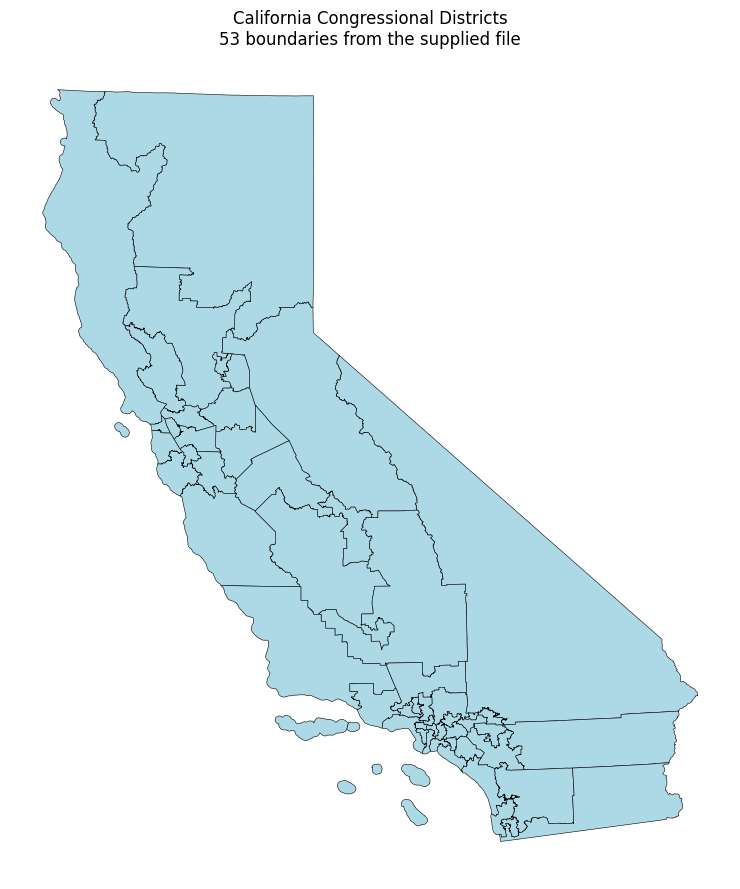

In [5]:
ax = projected.plot(figsize=(8, 9), color='lightblue', edgecolor='black', linewidth=0.4)
ax.set_title('California Congressional Districts\n53 boundaries from the supplied file')
ax.set_axis_off()
plt.tight_layout()
plt.savefig(figures / 'California_Districts.png', dpi=150)
plt.show()

## 4. Add the population values

This map uses the district-number merge as a plotting example. District 53 is gray.
The CSV values range from 760,065 to 760,067, so the full color scale covers only
two people. The colors should not be read as a large population difference.

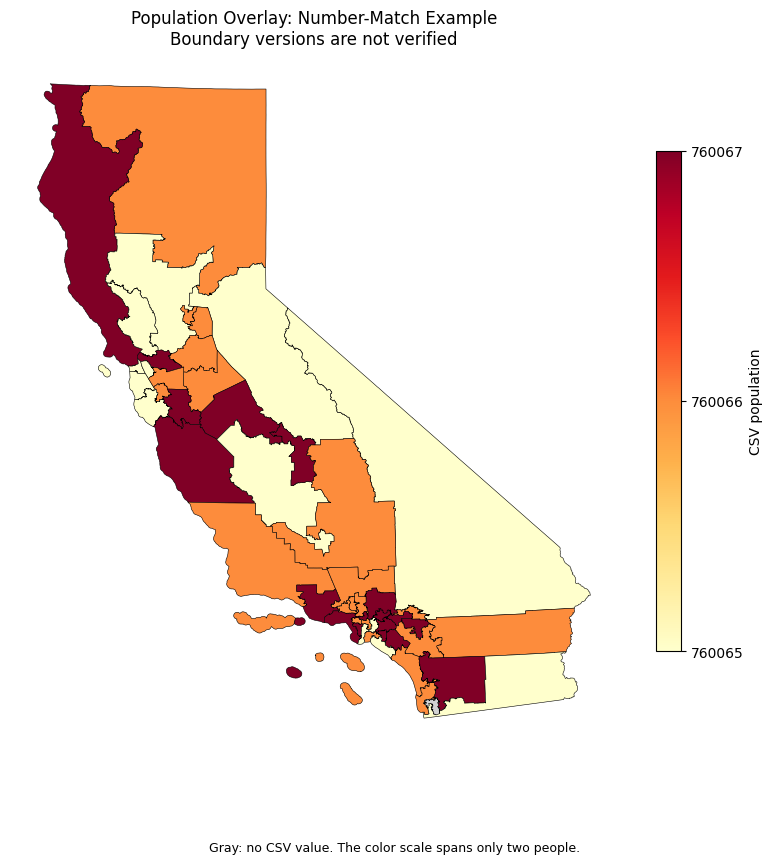

In [6]:
ax = projected.plot(column='POPULATION', cmap='YlOrRd', figsize=(8, 9),
                    edgecolor='black', linewidth=0.4, legend=True,
                    legend_kwds={'label': 'CSV population', 'shrink': 0.6,
                                 'ticks': [760065, 760066, 760067], 'format': '%.0f'},
                    missing_kwds={'color': 'lightgray'})
ax.set_title('Population Overlay: Number-Match Example\nBoundary versions are not verified')
ax.set_axis_off()
plt.figtext(0.5, 0.02, 'Gray: no CSV value. The color scale spans only two people.',
            ha='center', fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(figures / 'Population_Overlay_Example.png', dpi=150)
plt.show()

## 5. Make a heatmap

The files do not show where individual people live. For this exercise, one point
is placed inside each boundary with a number match and weighted by the CSV value.
These points are artificial. The heatmap shows how the plotting tool works;
it does not measure population density. The boundary mismatch still applies.

In [8]:
import folium
from folium.plugins import HeatMap
from IPython.display import display
from pathlib import Path

# Use one representative point for each district with a population value.
matched = projected.loc[projected['POPULATION'].notna()].copy()
points = matched.geometry.representative_point().to_crs(epsg=4326)
weights = matched['POPULATION'] / matched['POPULATION'].max()

heat_data = [
    [point.y, point.x, float(weight)]
    for point, weight in zip(points, weights)
]

# No online background tiles, to avoid the 403 error.
heat_map = folium.Map(
    location=[37.2, -119.5],
    zoom_start=6,
    tiles=None
)

HeatMap(heat_data, radius=25, blur=20).add_to(heat_map)

boundaries = joined[['district_id', 'geometry']].to_crs(epsg=4326)

folium.GeoJson(
    boundaries,
    style_function=lambda feature: {
        'fillOpacity': 0,
        'color': 'gray',
        'weight': 0.7
    },
    tooltip=folium.GeoJsonTooltip(
        fields=['district_id'],
        aliases=['District:']
    )
).add_to(heat_map)

# Show the whole state.
bounds = boundaries.total_bounds
heat_map.fit_bounds([
    [bounds[1], bounds[0]],
    [bounds[3], bounds[2]]
])

# Explain the limits of this example.
note = """
<div style="position:fixed;bottom:25px;left:10px;right:10px;
z-index:9999;background:white;padding:8px;">
Heatmap example only: artificial points, not population density.
CSV: 52 districts; map: 53. Matching boundary versions have not been confirmed.
</div>
"""
heat_map.get_root().html.add_child(folium.Element(note))

figures = Path('figures')
figures.mkdir(exist_ok=True)
heat_map.save(str(figures / 'California_Heatmap_Example.html'))

display(heat_map)

## A few observations

The population values in the CSV are almost the same: the difference between the
largest and smallest is only two people. The stronger colors in the population
map make that difference look more noticeable than it really is.

The bigger issue is the mismatch between the two files. Dropping district 53 would
not prove that the other district numbers refer to the same places. A matching
boundary file or a documented crosswalk would be needed for a valid population map.

The heatmap also needs care. Its darker areas depend on the artificial points and
the smoothing settings. They should not be described as areas where more people live.

## Sources

- Assignment files: `CA_Legislative_Districts.csv` and `california-congressional-districts.geojson`.
- [GeoPandas plotting guide](https://geopandas.org/en/stable/docs/user_guide/mapping.html)
- [Folium heatmap guide](https://python-visualization.github.io/folium/latest/user_guide/plugins/heatmap.html)